# Change a network: close a canal, fix a sea lane

A network can change after it is loaded. This notebook changes the sea network `world_sea` in two ways:

1. It closes the Suez Canal, computes a route from Shanghai to Rotterdam again, then opens the canal again.
2. It fixes a sea lane that crosses land in the north of Japan.

The last section saves the fixed network to a file.

You need scgraph, and [cartopy](https://scitools.org.uk/cartopy/) with [matplotlib](https://matplotlib.org) for the maps. The notebook downloads `world_sea` once (3.7 MB). It then runs in a few seconds.

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" cartopy matplotlib
import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt


from scgraph import GeoGraph

## 1. Load the network

`world_sea` holds the sea lanes and the ports of the world. A **node** is a point of the network, and an **edge** joins two nodes. Each node has an id: its position in `nodes`. Each node also has a **mode**: `sea` for a point of a sea lane, `port` for a port.

The function `get_sea_nodes_inside` finds nodes by their coordinates. The function `draw_map` draws lines and places on a map, with [cartopy](https://scitools.org.uk/cartopy/).

In [2]:
def draw_map(lines, places=(), extent=None, central_longitude=0, title=None, coasts="50m"):
    """A static map of lines and places, as a matplotlib figure.

    `lines` is a list of (points, color, label), with the points of a line as
    [latitude, longitude]. `places` is a list of (point, name). `extent` is
    [west, east, south, north] in degrees, or None for the whole world.
    `central_longitude` is the longitude in the middle of the map. `coasts` is
    the scale of the coasts: "110m" keeps a map of the whole world light.
    """
    figure = plt.figure(figsize=(9, 4.5))
    ax = figure.add_subplot(projection=ccrs.PlateCarree(central_longitude=central_longitude))
    if extent is None:
        ax.set_global()
    else:
        ax.set_extent(extent, crs=ccrs.PlateCarree())
    # The map fills the ocean, not the land: the land fill of cartopy fails on some regional maps
    ax.add_feature(cartopy.feature.OCEAN.with_scale(coasts), facecolor="#d6e6ef")
    ax.coastlines(coasts, linewidth=0.5)
    for points, color, label in lines:
        latitudes, longitudes = zip(*points)
        # Geodetic draws each step as a great circle, the line along which scgraph measures
        # lengths. It also cuts a line where the line crosses the edge of the map.
        ax.plot(longitudes, latitudes, color=color, linewidth=2, label=label, transform=ccrs.Geodetic())
    for (latitude, longitude), name in places:
        ax.plot(longitude, latitude, "ko", markersize=4, transform=ccrs.PlateCarree())
        ax.text(longitude, latitude, f"  {name}", fontsize=8, transform=ccrs.PlateCarree())
    if any(label for _, _, label in lines):
        ax.legend(loc="best", fontsize=8)
    ax.set_title(title)
    return figure


def get_sea_nodes_inside(geograph, south, west, north, east):
    """The ids of the sea nodes between two latitudes and two longitudes."""
    mode_names = [mode["name"] for mode in geograph.modes]
    return [
        node
        for node, (latitude, longitude) in enumerate(geograph.nodes)
        if south <= latitude <= north
        and west <= longitude <= east
        and mode_names[geograph.node_modes[node]] == "sea"
    ]


world_sea = GeoGraph.load_geograph("world_sea")
print(f"world_sea has {len(world_sea.nodes):,} nodes.")

world_sea has 43,233 nodes.


## 2. Close the Suez Canal

First, the shortest route from Shanghai to Rotterdam, with the canal open. The length is in kilometres.

In [3]:
SHANGHAI = {"latitude": 31.23, "longitude": 121.47}
ROTTERDAM = {"latitude": 51.95, "longitude": 4.14}

route_with_canal = world_sea.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"With the canal: {route_with_canal['length']:,.1f} km")

With the canal: 19,659.8 km


The canal runs from latitude 30 to latitude 31.2, near longitude 32.4. The sea nodes in this rectangle are the nodes of the canal.

`remove_edge(origin_id, destination_id)` removes the edge from one node to another. It returns the length of the removed edge, or `None` if there was no such edge. The next cell tries each pair of canal nodes, and keeps the lengths of the removed edges.

In [4]:
canal_nodes = get_sea_nodes_inside(world_sea, 30.0, 32.25, 31.2, 32.6)
print(f"{len(canal_nodes)} sea nodes in the canal")

removed_edges = {}
for origin in canal_nodes:
    for destination in canal_nodes:
        if origin != destination:
            length = world_sea.remove_edge(origin_id=origin, destination_id=destination)
            if length is not None:
                removed_edges[(origin, destination)] = length
print(f"{len(removed_edges)} edges removed: each section of the canal has one edge in each direction")

route_without_canal = world_sea.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"Without the canal: {route_without_canal['length']:,.1f} km")

5 sea nodes in the canal
8 edges removed: each section of the canal has one edge in each direction


Without the canal: 25,232.6 km


Without the canal, the shortest route goes east. It crosses the Pacific Ocean, goes through the Panama Canal, then crosses the Atlantic Ocean. It is about 5,600 km longer. On the map of the whole world below, this route leaves the right edge and comes back on the left edge.

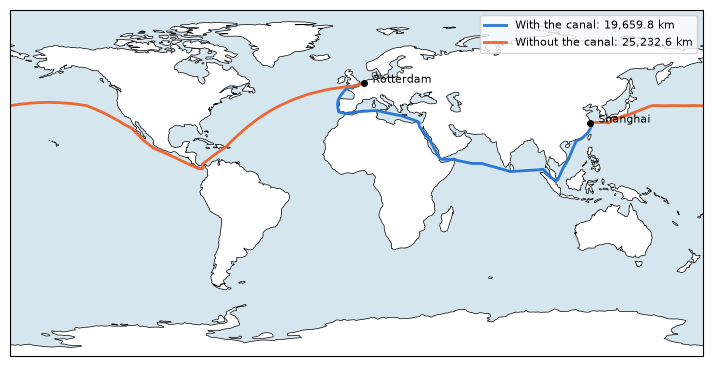

In [5]:
figure = draw_map(
    lines=[
        (route_with_canal["coordinate_path"], "#2a78d6", f"With the canal: {route_with_canal['length']:,.1f} km"),
        (route_without_canal["coordinate_path"], "#eb6834", f"Without the canal: {route_without_canal['length']:,.1f} km"),
    ],
    places=[([31.23, 121.47], "Shanghai"), ([51.95, 4.14], "Rotterdam")],
    coasts="110m",
)
plt.show()

`add_edge(origin_id, destination_id, distance)` adds an edge. The next cell opens the canal again: it adds back each removed edge, with its length.

In [6]:
for (origin, destination), length in removed_edges.items():
    world_sea.add_edge(origin_id=origin, destination_id=destination, distance=length)

route = world_sea.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"Canal open again: {route['length']:,.1f} km")

Canal open again: 19,659.8 km


## 3. Fix a sea lane that crosses land

The sea lanes of `world_sea` come from Eurostat SeaRoute. One of their edges crosses land in the north of Japan. The next cell computes a route from the coast off Akita to the coast off Hachinohe, and draws it on a detailed map.

Before the fix: 536.2 km


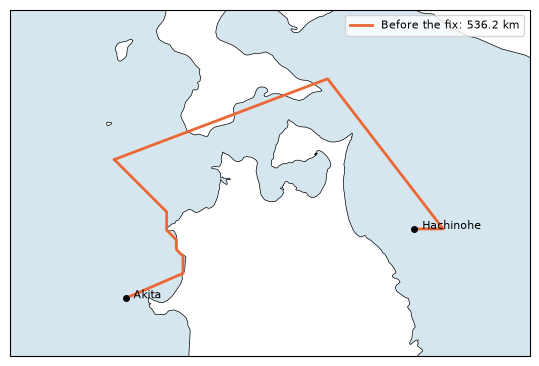

In [7]:
AKITA = {"latitude": 40.0, "longitude": 139.5}  # off the coast of Akita
HACHINOHE = {"latitude": 40.6, "longitude": 142.0}  # off the coast of Hachinohe

route_before = world_sea.get_shortest_path(origin_node=AKITA, destination_node=HACHINOHE)
print(f"Before the fix: {route_before['length']:,.1f} km")

TSUGARU = [138.5, 143, 39.5, 42.5]  # west, east, south, north
PLACES = [([40.0, 139.5], "Akita"), ([40.6, 142.0], "Hachinohe")]

figure = draw_map(
    lines=[(route_before["coordinate_path"], "#eb6834", f"Before the fix: {route_before['length']:,.1f} km")],
    places=PLACES,
    extent=TSUGARU,
    coasts="10m",
)
plt.show()

The route should pass through the Tsugaru Strait, between Honshu and Hokkaido. Instead, one straight edge goes from the node at (41.2, 139.4) to the node at (41.9, 141.25). This edge crosses the Oshima Peninsula of Hokkaido.

The function `find_node` below finds the id of a node from its coordinates. `remove_edge(..., symmetric=True)` then removes the edge in both directions.

In [8]:
def find_node(geograph, latitude, longitude):
    """The id of the node at a latitude and a longitude."""
    for node, point in enumerate(geograph.nodes):
        if abs(point[0] - latitude) < 1e-6 and abs(point[1] - longitude) < 1e-6:
            return node
    raise ValueError(f"No node at ({latitude}, {longitude})")


west_node = find_node(world_sea, 41.2, 139.4)
east_node = find_node(world_sea, 41.9, 141.25)
length = world_sea.remove_edge(origin_id=west_node, destination_id=east_node, symmetric=True)
print(f"Removed the edge between nodes {west_node} and {east_node}: {length:,.1f} km")

Removed the edge between nodes 38149 and 38145: 172.5 km


The new path goes through the strait, with two new points at sea:

- `add_coord_node` adds a node at a latitude and a longitude, and returns its id. `auto_edge=False` adds it without any edge. `mode="sea"` gives it the mode `sea`.
- `add_haversine_edge` adds an edge in both directions. Its length is the distance on the globe between the two nodes.

Three edges join the west node, the two new nodes and the east node.

After the fix: 551.3 km


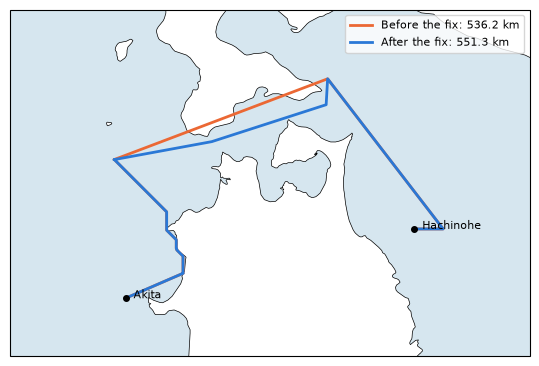

In [9]:
strait_west = world_sea.add_coord_node(
    coord_dict={"latitude": 41.3559, "longitude": 140.2468}, auto_edge=False, mode="sea"
)
strait_east = world_sea.add_coord_node(
    coord_dict={"latitude": 41.6757, "longitude": 141.2373}, auto_edge=False, mode="sea"
)
world_sea.add_haversine_edge(origin_idx=west_node, destination_idx=strait_west)
world_sea.add_haversine_edge(origin_idx=strait_west, destination_idx=strait_east)
world_sea.add_haversine_edge(origin_idx=strait_east, destination_idx=east_node)

route_after = world_sea.get_shortest_path(origin_node=AKITA, destination_node=HACHINOHE)
print(f"After the fix: {route_after['length']:,.1f} km")

figure = draw_map(
    lines=[
        (route_before["coordinate_path"], "#eb6834", f"Before the fix: {route_before['length']:,.1f} km"),
        (route_after["coordinate_path"], "#2a78d6", f"After the fix: {route_after['length']:,.1f} km"),
    ],
    places=PLACES,
    extent=TSUGARU,
    coasts="10m",
)
plt.show()

The new route stays at sea through the strait. It is a little longer, because it no longer cuts across the peninsula.

## 4. Save the fixed network

A change lives in memory only. The next `load_geograph("world_sea")` loads the network as it was published. To keep the fix, save the network to a file with `save_as_scgraph`, and load it later with `load_from_scgraph`.

The next cell saves the network to a file in the current folder, loads the file, and computes the route again.

In [10]:
world_sea.save_as_scgraph("world_sea_fixed.scgraph")

fixed = GeoGraph.load_from_scgraph("world_sea_fixed.scgraph")
route = fixed.get_shortest_path(origin_node=AKITA, destination_node=HACHINOHE)
print(f"Akita to Hachinohe on the saved network: {route['length']:,.1f} km")

Akita to Hachinohe on the saved network: 551.3 km


`save_as_geojson` writes the network as a GeoJSON file, which a tool such as [geojson.io](https://geojson.io) shows on a map. It helps to find the nodes and the edges to change.

## What to remember

- `remove_edge` and `add_edge` remove and add an edge between two nodes, by their ids. `symmetric=True` acts in both directions.
- `add_coord_node` adds a node at a latitude and a longitude, and returns its id.
- `add_haversine_edge` adds an edge whose length is the distance on the globe between two nodes.
- Find the ids of the nodes from their coordinates. The ids can change from one version of a network to the next.
- `save_as_scgraph` keeps a changed network in a file.